# Match two runs by train progress

Load full W&B histories into pandas and find the 100 pairs of logged steps minimizing
`abs(progress1 - progress2)`. Steps can repeat across pairs, and matches can cluster
in one progress range. No interpolation or monotonicity assumption is used.

Requirements: `wandb`, `pandas`, and `matplotlib`. Install them in this notebook's
kernel environment if necessary (e.g. `%pip install wandb pandas matplotlib`).
Authenticate with `wandb login` in a terminal, or run `wandb.login()` interactively.
The entity is the username/team before `/TwoSelectionMethods` in the W&B URL.
W&B `scan_history()` retrieves unsampled history:
[API reference](https://docs.wandb.ai/models/ref/python/public-api/run#method-run-scan_history).

The repository logs total training steps as W&B's `_step`; these are not epoch numbers.

Select the `online-bs-p100` conda environment as the notebook kernel in VS Code.


In [129]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import wandb
from IPython.display import display

ENTITY = "miller-ml-research"
RUN_1 = f"{ENTITY}/TwoSelectionMethods/yelmjxhf"  # threshold 0.2
RUN_2 = f"{ENTITY}/TwoSelectionMethods/8qgftw5w"  # threshold 0.4
TOP_K = 5
MIN_STEP = None  # Inclusive lower bound for BOTH runs; set after the shared training phase.
MAX_STEP = None
MIN_PROGRESS = 0.23
MAX_PROGRESS = 0.232
# All bounds are inclusive and apply to both runs. None disables a bound.
TARGET_PROGRESS = 0.4
REFRESH_CACHE = False

# Works with a kernel started from either the repository root or notebooks/.
cwd = Path.cwd()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "REPO_GUIDE.md").exists()), cwd)
OUTPUT_DIR = ROOT / "analysis_outputs" / "train_progress_matching"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUTPUT_DIR)

Outputs: /home/todd30ap/online-batch-selection/analysis_outputs/train_progress_matching


## Load and inspect histories

Cache each run independently. Set `REFRESH_CACHE = True` to download again.
Missing or nonnumeric values are removed; duplicate steps are rejected to avoid
ambiguous pairs. These are metric histories, not W&B summary values.

In [130]:
def load_progress(run_path, refresh=False):
    parts = run_path.strip("/").split("/")
    if len(parts) != 3 or parts[0] == "YOUR_ENTITY":
        raise ValueError("Set a full run path: entity/project/run_id.")
    cache = OUTPUT_DIR.joinpath("histories", *parts).with_suffix(".csv")
    if cache.exists() and not refresh:
        frame = pd.read_csv(cache)
        print("Loaded cache:", cache)
    else:
        run = wandb.Api().run(run_path)
        rows = list(run.scan_history(keys=["_step", "train_progress"]))
        frame = pd.DataFrame(rows, columns=["_step", "train_progress"])
        frame = frame.rename(columns={"_step": "step"})
        cache.parent.mkdir(parents=True, exist_ok=True)
        frame.to_csv(cache, index=False)
        print("Downloaded:", run_path)

    frame = frame[["step", "train_progress"]].apply(pd.to_numeric, errors="coerce")
    frame = frame.replace([float("inf"), -float("inf")], float("nan"))
    frame = frame.dropna().sort_values("step").reset_index(drop=True)
    if frame.empty:
        raise ValueError(f"No valid train_progress records for {run_path}.")
    if frame["step"].duplicated().any():
        raise ValueError(f"Duplicate steps found in {run_path}.")
    return frame

df1 = load_progress(RUN_1, REFRESH_CACHE)
df2 = load_progress(RUN_2, REFRESH_CACHE)

display(pd.DataFrame([
    {"run": name, "records": len(frame),
     "first_step": frame.step.min(), "last_step": frame.step.max(),
     "min_progress": frame.train_progress.min(),
     "max_progress": frame.train_progress.max()}
    for name, frame in [(RUN_1, df1), (RUN_2, df2)]
]))
display(df1.head(), df2.head())

Loaded cache: /home/todd30ap/online-batch-selection/analysis_outputs/train_progress_matching/histories/miller-ml-research/TwoSelectionMethods/yelmjxhf.csv
Loaded cache: /home/todd30ap/online-batch-selection/analysis_outputs/train_progress_matching/histories/miller-ml-research/TwoSelectionMethods/8qgftw5w.csv


,run,records,first_step,last_step,min_progress,max_progress
0,miller-ml-research/TwoSelectionMethods/yelmjxhf,1001,0,157000,0.000634,0.994902
1,miller-ml-research/TwoSelectionMethods/8qgftw5w,1001,0,157000,0.000634,0.995600


,step,train_progress
0,0,0.000634
1,157,0.093843
2,314,0.122858
3,471,0.175551
4,628,0.205260


,step,train_progress
0,0,0.000634
1,157,0.093843
2,314,0.122858
3,471,0.175551
4,628,0.205260


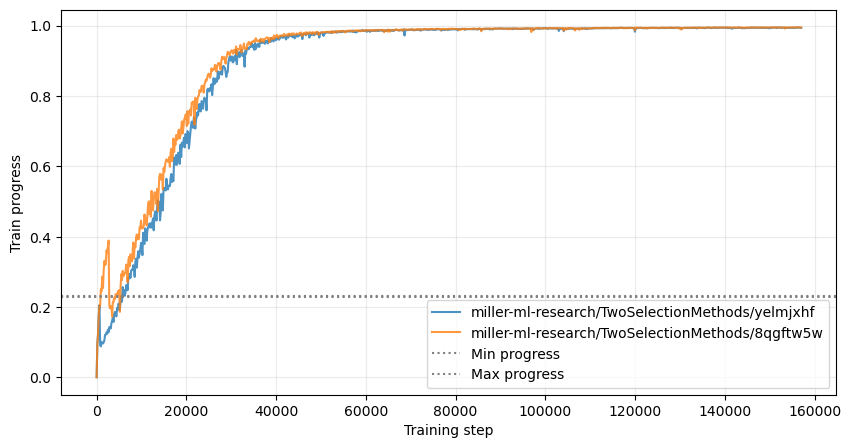

In [131]:
def plot_curves():
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df1.step, df1.train_progress, label=RUN_1, alpha=0.8)
    ax.plot(df2.step, df2.train_progress, label=RUN_2, alpha=0.8)
    for bound, label in [(MIN_STEP, "Min step"), (MAX_STEP, "Max step")]:
        if bound is not None:
            ax.axvline(bound, color="gray", linestyle=":", label=label)
    for bound, label in [(MIN_PROGRESS, "Min progress"), (MAX_PROGRESS, "Max progress")]:
        if bound is not None:
            ax.axhline(bound, color="gray", linestyle=":", label=label)
    ax.set(xlabel="Training step", ylabel="Train progress")
    ax.legend()
    ax.grid(alpha=0.25)
    return fig, ax

plot_curves()
plt.show()

## Globally closest step pairs

Compare all logged points across runs with pandas cross joins. Chunking bounds
temporary memory use; keeping only the best K from each chunk preserves the exact
global top K. Runtime still scales with the product of the two history lengths.
Ties are ordered by `s1`, then `s2`.

`mean_progress` is the horizontal-line height halfway between the two values.
Each point is `progress_gap / 2` away from that line.

Both points must satisfy all enabled bounds: `MIN_STEP`, `MAX_STEP`,
`MIN_PROGRESS`, and `MAX_PROGRESS`. Bounds are inclusive; `None` disables a bound.
Set them in the inputs cell and rerun the notebook. Full histories remain cached
and plotted. Matching and target lookup use only eligible points.


In [132]:
def closest_step_pairs(df1, df2, k=100, max_chunk_pairs=1_000_000):
    if k < 1 or max_chunk_pairs < 1:
        raise ValueError("k and max_chunk_pairs must be positive.")
    if df1.empty or df2.empty:
        raise ValueError("Both histories must contain data.")
    left = df1.rename(columns={"step": "s1", "train_progress": "progress1"})
    right = df2.rename(columns={"step": "s2", "train_progress": "progress2"})
    order = ["progress_gap", "s1", "s2"]
    right_chunk_size = min(len(right), max_chunk_pairs)
    left_chunk_size = max(1, max_chunk_pairs // right_chunk_size)
    best = None
    for i in range(0, len(left), left_chunk_size):
        for j in range(0, len(right), right_chunk_size):
            pairs = left.iloc[i:i + left_chunk_size].merge(
                right.iloc[j:j + right_chunk_size], how="cross"
            )
            pairs["progress_gap"] = (pairs.progress1 - pairs.progress2).abs()
            candidates = pairs.sort_values(order).head(k)
            best = candidates if best is None else pd.concat(
                [best, candidates], ignore_index=True
            ).sort_values(order).head(k)
    best = best.sort_values(order).reset_index(drop=True)
    best["mean_progress"] = (best.progress1 + best.progress2) / 2
    best.index += 1
    best.index.name = "rank"
    return best

def eligible_steps(frame, run_name, min_step=None, max_step=None,
                   min_progress=None, max_progress=None):
    mask = pd.Series(True, index=frame.index)
    for column, lower, upper in [
        ("step", min_step, max_step),
        ("train_progress", min_progress, max_progress),
    ]:
        for value in [lower, upper]:
            if value is not None and (pd.isna(value) or abs(value) == float("inf")):
                raise ValueError(f"{column} bounds must be finite numbers or None.")
        if lower is not None and upper is not None and lower > upper:
            raise ValueError(f"{column}: minimum must be <= maximum.")
        if lower is not None:
            mask &= frame[column] >= lower
        if upper is not None:
            mask &= frame[column] <= upper
    filtered = frame.loc[mask].copy()
    if filtered.empty:
        raise ValueError(f"{run_name}: no records satisfy the step and progress bounds. "
                         "Widen the bounds in the inputs cell.")
    return filtered

bounds = dict(min_step=MIN_STEP, max_step=MAX_STEP,
              min_progress=MIN_PROGRESS, max_progress=MAX_PROGRESS)
match_df1 = eligible_steps(df1, RUN_1, **bounds)
match_df2 = eligible_steps(df2, RUN_2, **bounds)
print("Inclusive bounds (None = unrestricted):", bounds)
print(f"Eligible records: {len(match_df1):,} in run 1; {len(match_df2):,} in run 2")
print(f"Comparing {len(match_df1) * len(match_df2):,} candidate pairs")
closest = closest_step_pairs(match_df1, match_df2, TOP_K)
display(closest)
print("Unique steps:", closest.s1.nunique(), "in run 1;",
      closest.s2.nunique(), "in run 2")

ValueError: miller-ml-research/TwoSelectionMethods/8qgftw5w: no records satisfy the step and progress bounds. Widen the bounds in the inputs cell.

## Inspect a selected match

Choose a rank from the results. The horizontal line passes halfway between the
matched progress values; markers show the actual logged points.

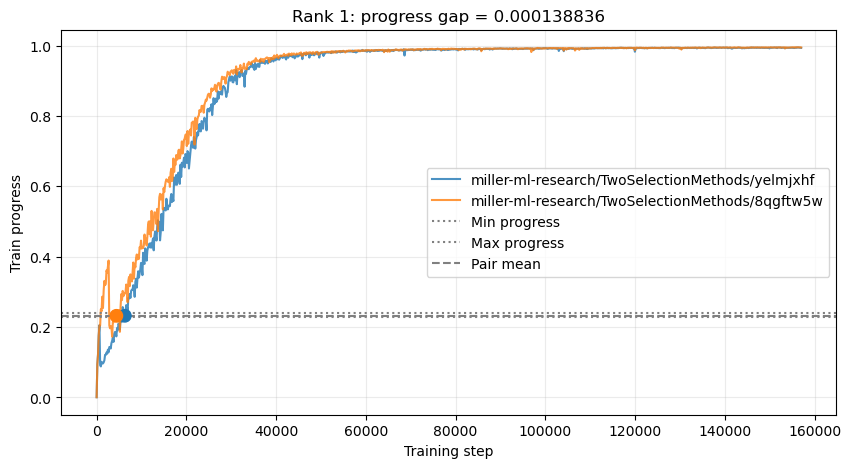

,value
s1,6280.000000
progress1,0.232161
s2,4396.000000
progress2,0.232022
progress_gap,0.000139
mean_progress,0.232091


In [ ]:
MATCH_RANK = 1
match = closest.loc[MATCH_RANK]

fig, ax = plot_curves()
ax.axhline(match.mean_progress, color="gray", linestyle="--", label="Pair mean")
ax.scatter([match.s1, match.s2], [match.progress1, match.progress2],
           color=["C0", "C1"], s=80, zorder=5)
ax.set_title(f"Rank {MATCH_RANK}: progress gap = {match.progress_gap:.6g}")
ax.legend()
plt.show()
display(match.to_frame("value"))

## Find steps nearest a chosen horizontal line

This independently minimizes distance to `TARGET_PROGRESS` for each run.
It is different from minimizing the gap between runs. If the target lies outside
a run's eligible progress range, the nearest observed value is still returned.
Ties choose the earliest logged step.
All enabled step and progress bounds apply here as well.


,run,step,train_progress,target,min_step,max_step,min_progress,max_progress,distance_to_target,target_in_eligible_range
0,miller-ml-research/TwoSelectionMethods/yelmjxhf,5966.0,0.235377,0.4,None,None,0.23,0.24,0.164623,False
1,miller-ml-research/TwoSelectionMethods/8qgftw5w,4239.0,0.236791,0.4,None,None,0.23,0.24,0.163209,False


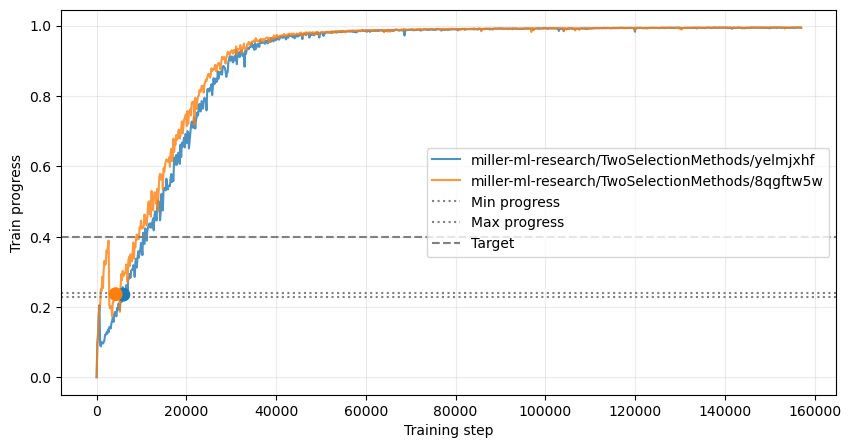

In [ ]:
target_rows = []
for run_path, frame in [(RUN_1, match_df1), (RUN_2, match_df2)]:
    point = frame.loc[(frame.train_progress - TARGET_PROGRESS).abs().idxmin()]
    target_rows.append({
        "run": run_path, "step": point.step,
        "train_progress": point.train_progress,
        "target": TARGET_PROGRESS, **bounds,
        "distance_to_target": abs(point.train_progress - TARGET_PROGRESS),
        "target_in_eligible_range": (
            frame.train_progress.min() <= TARGET_PROGRESS <= frame.train_progress.max()
        ),
    })
target_matches = pd.DataFrame(target_rows)
display(target_matches)

fig, ax = plot_curves()
ax.axhline(TARGET_PROGRESS, color="gray", linestyle="--", label="Target")
ax.scatter(target_matches.step, target_matches.train_progress,
           color=["C0", "C1"], s=80, zorder=5)
ax.legend()
plt.show()

## Export results

Exports include full run paths so the step pairs retain their provenance.
Re-running this cell replaces the result CSVs; cached histories stay separate.

In [ ]:
closest.assign(run1=RUN_1, run2=RUN_2, **bounds).to_csv(
    OUTPUT_DIR / "closest_train_progress_pairs.csv", index=True
)
target_matches.to_csv(OUTPUT_DIR / "target_progress_steps.csv", index=False)
print("Saved results to", OUTPUT_DIR)

Saved results to /home/todd30ap/online-batch-selection/analysis_outputs/train_progress_matching


In [133]:
# Enter exact logged steps: (step in RUN_1, step in RUN_2).
# Uses the full loaded histories df1/df2, irrespective of matching bounds.
# Run the inputs and history-loading cells first.
step_pairs = [
    (10676, 8478),
    (6280, 4396),
    (15857, 14758),
    (23079, 20724),
    (34383, 31086),
    (77558, 63428),
    (154017, 135648)
]


def progress_for_step_pairs(step_pairs, df1, df2):
    result = pd.DataFrame(step_pairs, columns=["s1", "s2"])
    result["progress1"] = result["s1"].map(df1.set_index("step")["train_progress"])
    result["progress2"] = result["s2"].map(df2.set_index("step")["train_progress"])
    result["progress_gap"] = (result["progress1"] - result["progress2"]).abs()
    result["mean_progress"] = (result["progress1"] + result["progress2"]) / 2
    result = result[["s1", "progress1", "s2", "progress2", "progress_gap", "mean_progress"]]
    result.index += 1
    result.index.name = "pair"
    return result


print("Model 1:", RUN_1)
print("Model 2:", RUN_2)
step_pair_table = progress_for_step_pairs(step_pairs, df1, df2)
for step_column, progress_column, model_name in [
    ("s1", "progress1", "Model 1"), ("s2", "progress2", "Model 2"),
]:
    missing = step_pair_table.loc[step_pair_table[progress_column].isna(), step_column].tolist()
    if missing:
        print(f"{model_name}: no logged progress at steps {missing}; shown as NaN (no interpolation).")
display(step_pair_table)


Model 1: miller-ml-research/TwoSelectionMethods/yelmjxhf
Model 2: miller-ml-research/TwoSelectionMethods/8qgftw5w


,s1,progress1,s2,progress2,progress_gap,mean_progress
pair,,,,,,
1,10676,0.379485,8478,0.379395,9.019463e-05,0.379440
2,6280,0.232161,4396,0.232022,1.388358e-04,0.232091
3,15857,0.534498,14758,0.534478,1.959793e-05,0.534488
4,23079,0.756853,20724,0.756929,7.587853e-05,0.756891
5,34383,0.941060,31086,0.941045,1.513920e-05,0.941053
6,77558,0.987601,63428,0.987601,1.199861e-10,0.987601
7,154017,0.993911,135648,0.993911,6.761909e-08,0.993911
